In [12]:
import logging
import pandas as pd
from audio_files import GCStore, AudioExtenstion, AudioFile
from signal_treatment import extract_spectral_distribution, plot_spectral, band_levels, standard_bands, plot_bands, plot_bands_over_time

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
logging.basicConfig(
    level=logging.WARNING,  
    format="%(asctime)s %(levelname)s %(name)s: %(message)s",
    force=True,
)
logging.getLogger("audio_files").setLevel(logging.INFO)

In [3]:
BUCKET = "noaa-passive-bioacoustic"
FILES_PREFIX = "sefsc"
store = GCStore(bucket=BUCKET)
start_date = pd.Timestamp(2016, 7, 31)
end_date = pd.Timestamp(2016, 8,1)

In [4]:
files = store.list_files(prefix=FILES_PREFIX)

In [5]:
files = GCStore.filter_files(
    filenames=files,
    extentions=[AudioExtenstion.FLAC],
    start_date=start_date,
    end_date=end_date)

In [6]:
aud = AudioFile(filename=files[0], store=store)

2026-11-22 15:40:10,126 INFO audio_files:  GOM_EF_01_160731_115002.x.flac  fs=2000  1 segment(s)  181 minutes


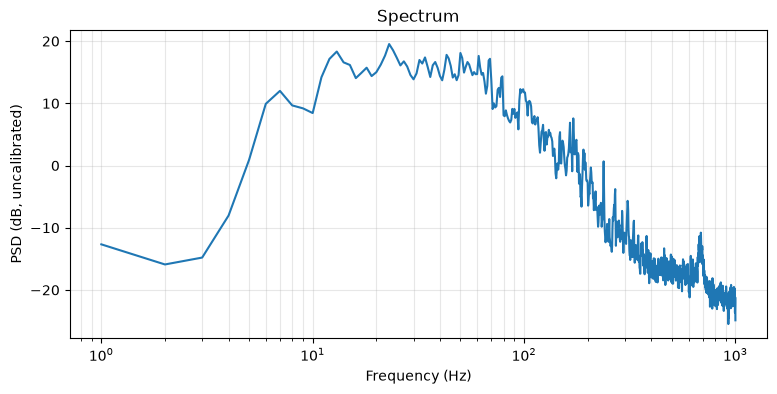

In [11]:
to = aud.timestamp
t1 = aud.timestamp  + pd.Timedelta(hours=3)

spectral_densities = extract_spectral_distribution(audio_file=aud, t0=to, t1=t1)

times = spectral_densities[0]
freqs = spectral_densities[1]
psds = spectral_densities[2]
instant = 80
plot_spectral(freqs=freqs, psd=psds[instant], calibrated=False)

In [8]:
bands_def = standard_bands(fmax=freqs[-1])

bands_lvl = band_levels(
    freqs=freqs,
    psd_db=psds[instant],
    bands=bands_def)

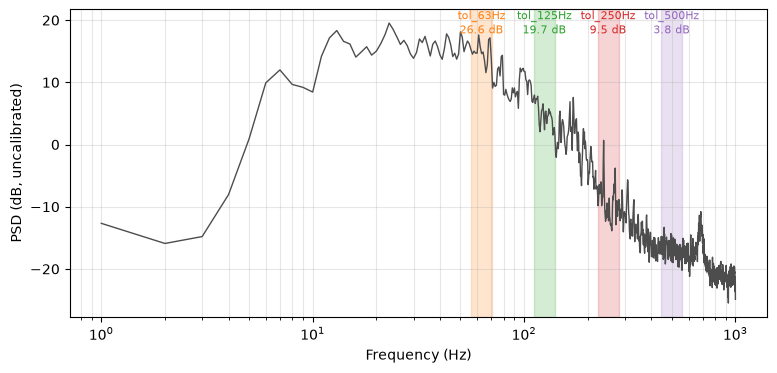

In [9]:
plot_bands(freqs=freqs, psd=psds[instant], bands_levels=bands_lvl, bands_def=bands_def)

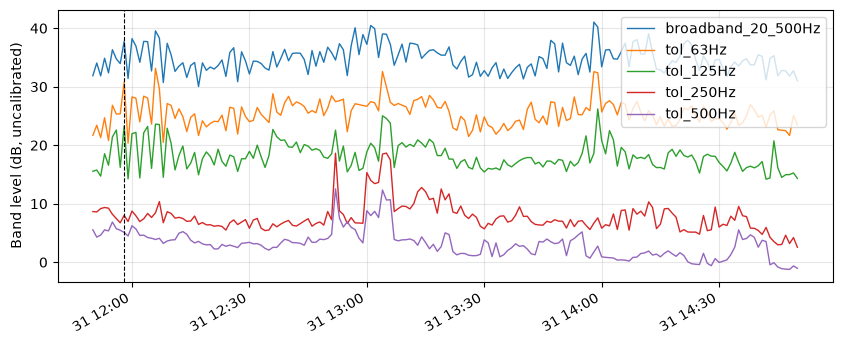

In [14]:
plot_bands_over_time(times=times, freqs=freqs, psds=psds, bands_def=bands_def, instant=8)